# LAB 2 - BÀI 3: SAI PHÂN & KIỂM ĐỊNH LẠI (ADF LẦN 2)
**Dataset 1:** `a10.csv` (Doanh số bán lẻ theo tháng)

### 📌 Yêu cầu của đề:
- Thực hiện sai phân bậc 1.
- Vẽ lại đồ thị chuỗi thời gian sau khi sai phân.
- Kiểm định ADF lần 2.

### ❓ Câu hỏi cần trả lời:
- Sau sai phân, chuỗi đã dừng chưa?
- Giá trị $d$ trong mô hình ARIMA là bao nhiêu?

---
*Ghi chú:*
- *Các thư viện sử dụng: `numpy`, `pandas`, `matplotlib`, `statsmodels`.*
- *Các vị trí trả lời trọng tâm được đánh dấu bằng **>>> CÂU HỎI** trong phần code.*

In [2]:
"""
LAB 2 - BÀI 3: SAI PHÂN & KIỂM ĐỊNH LẠI (ADF lần 2)
Dataset 1: a10.csv (doanh số theo tháng)

Người làm (W): Hoàng Phúc
Người quan sát (O): Minh Quân, Thanh Thùy, Minh Hòa
"""
# Không cần lệnh !pip install vì Colab đã có sẵn các thư viện này
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# Tạo thư mục lưu hình ảnh
os.makedirs("figures", exist_ok=True)
URL = "https://raw.githubusercontent.com/selva86/datasets/master/a10.csv"

### 0. HIỂU SAI PHÂN BẰNG VÍ DỤ NHỎ

In [3]:
# Sai phân bậc 1 = giá trị này trừ giá trị trước đó:  y'[t] = y[t] - y[t-1]
# Mục đích: bỏ XU HƯỚNG, để trung bình của chuỗi không còn thay đổi theo thời gian.
tang_deu = pd.Series([10, 12, 14, 16, 18])      # tăng đều mỗi bước 2
tang_nhanh = pd.Series([1, 4, 9, 16, 25])       # tăng nhanh dần (bình phương)

print("Tăng đều      :", tang_deu.tolist())
print("  sai phân 1  :", tang_deu.diff().dropna().tolist(), "-> hằng số, hết xu hướng => d = 1")
print("Tăng nhanh dần:", tang_nhanh.tolist())
print("  sai phân 1  :", tang_nhanh.diff().dropna().tolist(), "-> vẫn còn xu hướng tăng")
print("  sai phân 2  :", tang_nhanh.diff().diff().dropna().tolist(), "-> hằng số => d = 2")
print("=> Cần sai phân bao nhiêu lần để hết xu hướng thì đó chính là d.")

Tăng đều      : [10, 12, 14, 16, 18]
  sai phân 1  : [2.0, 2.0, 2.0, 2.0] -> hằng số, hết xu hướng => d = 1
Tăng nhanh dần: [1, 4, 9, 16, 25]
  sai phân 1  : [3.0, 5.0, 7.0, 9.0] -> vẫn còn xu hướng tăng
  sai phân 2  : [2.0, 2.0, 2.0] -> hằng số => d = 2
=> Cần sai phân bao nhiêu lần để hết xu hướng thì đó chính là d.


### 1. ĐỌC DỮ LIỆU

In [4]:
# Vì sao chuyển 'date' thành index thời gian? Để pandas biết đây là chuỗi thời gian
# (thứ tự và khoảng cách giữa các điểm có ý nghĩa), từ đó mới dùng được diff(), rolling()...
df = pd.read_csv(URL, parse_dates=["date"], index_col="date")
series = df["value"].asfreq("MS")      # MS = đầu mỗi tháng, khai báo dữ liệu theo tháng
print("Số điểm:", len(series), "| từ", series.index.min().date(), "đến", series.index.max().date())

Số điểm: 204 | từ 1991-07-01 đến 2008-06-01


### 2 & 3. HÀM ADF VÀ TẠO CÁC PHIÊN BẢN SAI PHÂN

In [5]:
# H0 của ADF: chuỗi CÓ nghiệm đơn vị, tức KHÔNG dừng.
# H1: chuỗi dừng.
# p-value <= 0.05 -> bác bỏ H0 -> chuỗi DỪNG.
def adf_report(x, name):
    x = x.dropna()
    stat, p, lags, nobs, crit, _ = adfuller(x, regression="c", autolag="AIC")
    kq = "DỪNG" if p <= 0.05 else "KHÔNG DỪNG"
    print(f"{name:<38} ADF = {stat:8.4f} | p-value = {p:.4f} | {kq}")
    return p

y_log = np.log(series)               # log: làm dao động đều hơn
d1 = series.diff()                   # sai phân bậc 1 (chuỗi gốc)
d2 = series.diff().diff()            # sai phân bậc 2 (chuỗi gốc)
log_d1 = y_log.diff()                # log + sai phân bậc 1
log_d1_s12 = y_log.diff().diff(12)   # log + sai phân 1 + sai phân mùa 12

### 4. KIỂM ĐỊNH ADF LẦN 1 VÀ LẦN 2

In [6]:
print("KẾT QUẢ ADF (H0: chuỗi không dừng)\n")
p0 = adf_report(series, "Lần 1 - Chuỗi gốc")
p1 = adf_report(d1, "Lần 2 - Sai phân bậc 1 (không log)")
p2 = adf_report(d2, "Tham khảo - Sai phân bậc 2")
pl = adf_report(y_log, "Tham khảo - Chỉ log")
pl1 = adf_report(log_d1, "Lần 2 (có log) - Log + sai phân 1")
pls = adf_report(log_d1_s12, "Tham khảo - Log + sai phân 1 + mùa 12")

KẾT QUẢ ADF (H0: chuỗi không dừng)

Lần 1 - Chuỗi gốc                      ADF =   3.1452 | p-value = 1.0000 | KHÔNG DỪNG
Lần 2 - Sai phân bậc 1 (không log)     ADF =  -2.4952 | p-value = 0.1167 | KHÔNG DỪNG
Tham khảo - Sai phân bậc 2             ADF = -10.2923 | p-value = 0.0000 | DỪNG
Tham khảo - Chỉ log                    ADF =  -0.9887 | p-value = 0.7574 | KHÔNG DỪNG
Lần 2 (có log) - Log + sai phân 1      ADF =  -4.5194 | p-value = 0.0002 | DỪNG
Tham khảo - Log + sai phân 1 + mùa 12  ADF =  -4.7855 | p-value = 0.0001 | DỪNG


/tmp/ipykernel_1309/2430538546.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, lags, nobs, crit, _ = adfuller(x, regression="c", autolag="AIC")
/tmp/ipykernel_1309/2430538546.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, lags, nobs, crit, _ = adfuller(x, regression="c", autolag="AIC")
/tmp/ipykernel_1309/2430538546.py:6: FutureWarning: adfuller

### 5. VẼ ĐỒ THỊ: CHUỖI TRƯỚC VÀ SAU SAI PHÂN

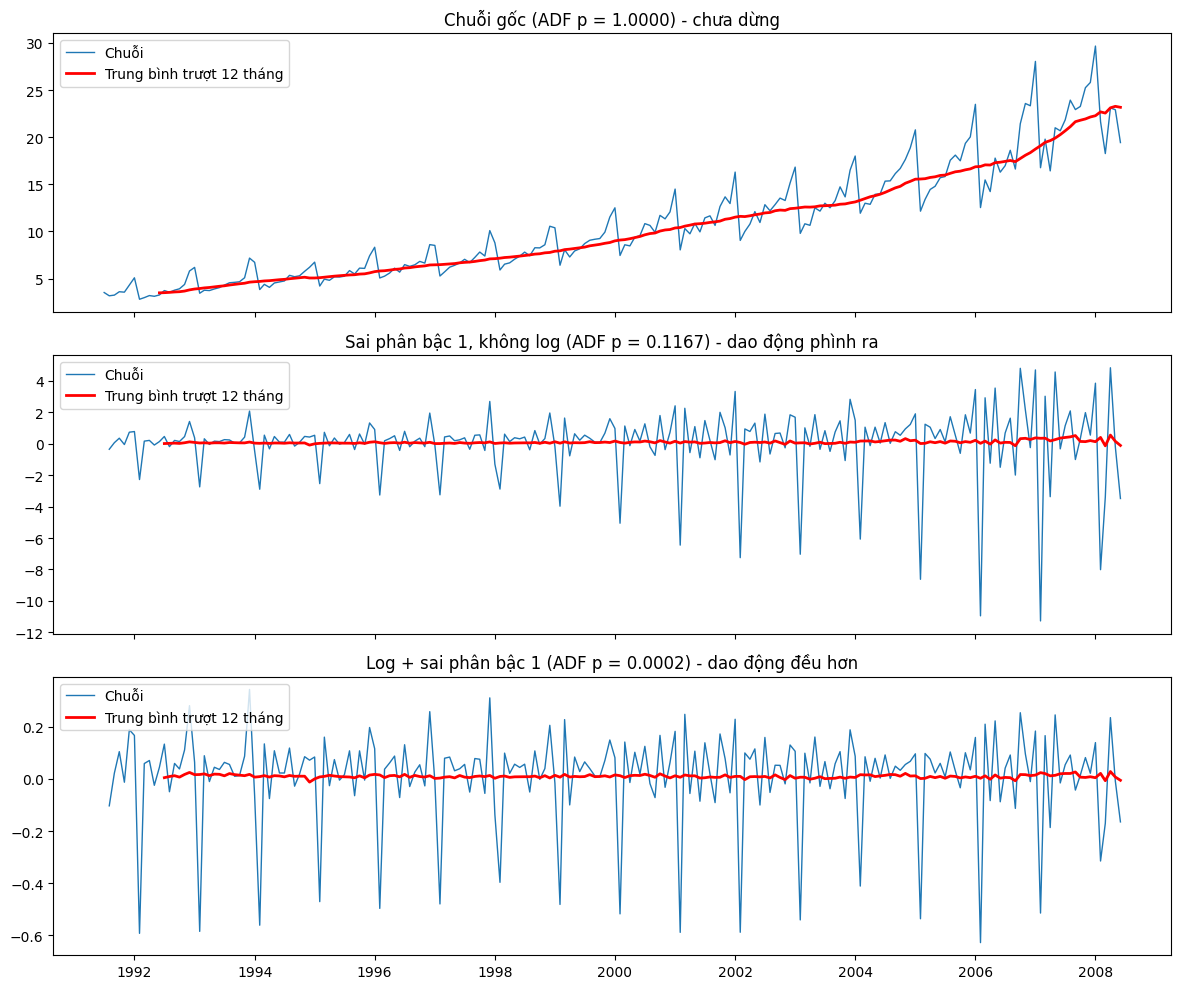

In [7]:
# Cách nhìn đồ thị để nói "dừng hay chưa":
#   - Đường trung bình trượt (đỏ) có nằm ngang quanh một mức không?  Nằm ngang -> kỳ vọng ổn định.
#   - Độ dao động có đều không (phình ra hay thu lại)?  Đều -> phương sai ổn định.
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, x, title in [
    (axes[0], series, f"Chuỗi gốc (ADF p = {p0:.4f}) - chưa dừng"),
    (axes[1], d1, f"Sai phân bậc 1, không log (ADF p = {p1:.4f}) - dao động phình ra"),
    (axes[2], log_d1, f"Log + sai phân bậc 1 (ADF p = {pl1:.4f}) - dao động đều hơn"),
]:
    x = x.dropna()
    ax.plot(x, label="Chuỗi", lw=1)
    ax.plot(x.rolling(12).mean(), color="red", lw=2, label="Trung bình trượt 12 tháng")
    ax.set_title(title)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("figures/bai3_sai_phan.png", dpi=150)
plt.show()

### 6. KẾT LUẬN (Trả lời câu hỏi)
**>>> CÂU HỎI 1: Sau sai phân, chuỗi đã dừng chưa?**
- Sai phân bậc 1 trên chuỗi gốc: p-value > 0.05 -> CHƯA dừng.
  Vì sai phân chỉ bỏ xu hướng, nhưng dao động của dataset a10 vẫn phình to dần.
- Sau khi lấy log rồi sai phân bậc 1: p-value <= 0.05 -> ĐÃ dừng.
  Log làm dao động đều hơn, sai phân bỏ xu hướng.

**>>> CÂU HỎI 2: Giá trị d trong ARIMA là bao nhiêu?**
- **d = 1** (số lần sai phân thường), áp dụng sau khi lấy log.
- Dữ liệu còn mùa vụ chu kỳ 12 tháng, nên với SARIMA cần thêm D = 1, s = 12.
- Không chọn d = 2 vì sai phân quá nhiều (over-differencing) làm mất thông tin và tăng nhiễu.